In [1]:
! pip install pandas requests






   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.9 MB 3.3 MB/s eta 0:00:03
   -------------------- ------------------- 5.5/10.9 MB 11.2 MB/s eta 0:00:01
   ---------------------------- ----------- 7.9/10.9 MB 11.4 MB/s eta 0:00:01
   ----------------------------------- ---- 9.7/10.9 MB 11.3 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 10.4 MB/s  0:00:01
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---------- ----------------------------- 3.4/12.7 MB 15.5 MB/s eta 0:00:01
   --------------------- ------------------ 6.8/12.7 MB 16.6 MB/s eta 0:00:01
   -------------------------------------- - 12.3/12.7 MB 19.5 MB/s eta 0:00:01
   ---------------------------------------- 12.7/12.7 MB 19.0 MB/s  0:00:00

   ---------------------------------------- 0/7 [urllib3]
   ------------------------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import requests
from pathlib import Path
import pandas as pd

# Определяем имена файлов, чтобы они точно совпадали
VISITS_FILE = "visits_api.csv"
REGS_FILE = "regs_api.csv"

# Если файлов ещё нет — скачиваем их из API
if not Path(VISITS_FILE).exists() or not Path(REGS_FILE).exists():
    print("Скачиваем данные из API...")
    
    # Важно: в тестах API доступен по адресу http://localhost:3000
    # Если ты запускаешь локально без Docker, этот блок может упасть, но для тестов на Гитхабе он обязателен
    try:
        visits_resp = requests.get("http://localhost:3000/visits?begin=2023-03-01&end=2023-04-02")
        regs_resp = requests.get("http://localhost:3000/registrations?begin=2023-03-01&end=2023-04-02")
        
        visits_resp.raise_for_status()
        regs_resp.raise_for_status()
        
        # Сохраняем как CSV (так требует логика твоего проекта)
        Path(VISITS_FILE).write_text(visits_resp.text)
        Path(REGS_FILE).write_text(regs_resp.text)
        print("Данные скачаны и сохранены.")
    except requests.exceptions.ConnectionError:
        print("⚠️ Не удалось подключиться к API (это нормально при локальном запуске без Docker).")
        print("Проверь, что у тебя есть локальные файлы visits_api.csv и regs_api.csv для работы.")
else:
    print("Файлы уже есть, пропускаем скачивание.")


Файлы уже есть, пропускаем скачивание.


In [2]:
import pandas as pd
import requests

print("Библиотеки установлены! Версия pandas:", pd.__version__)



Библиотеки установлены! Версия pandas: 3.1.1


In [3]:
import pandas as pd

# Загружаем данные из файлов, сохранённых на прошлом шаге
visits = pd.read_csv('visits_api.csv')
regs = pd.read_csv('regs_api.csv')

# Приводим даты к datetime и переименовываем колонки как раньше
visits = visits.rename(columns={'visit_id': 'uuid', 'datetime': 'date'})
visits['date_dt'] = pd.to_datetime(visits['date'])

regs = regs.rename(columns={'datetime': 'date'})
regs['date_dt'] = pd.to_datetime(regs['date'])

print(f"Визитов: {len(visits)}, регистраций: {len(regs)}")


Визитов: 263459, регистраций: 21836


In [6]:
import pandas as pd

# === Шаг 1. Убираем ботов из визитов (по слову bot в User-Agent) ===
print(f"Визитов до фильтрации: {len(visits)}")

visits_clean = visits[
    (~visits['user_agent'].str.contains('bot', case=False, na=False))
    & (visits['platform'] != 'bot')
].copy()

print(f"Визитов после удаления ботов: {len(visits_clean)}")
print(f"Удалено ботов: {len(visits) - len(visits_clean)}")

# === Шаг 2. Берём только ПОСЛЕДНИЙ визит для каждого visit_id ===
visits_clean = visits_clean.sort_values('date_dt')
visits_last = visits_clean.drop_duplicates(subset='uuid', keep='last')
print(f"Визитов после удаления повторных заходов: {len(visits_last)}")

# === Шаг 3. Группируем визиты по дате и платформе ===
visits_agg = (
    visits_last
    .assign(date_group=visits_last['date_dt'].dt.floor('D'))
    .groupby(['date_group', 'platform'], as_index=False)
    .size()
    .rename(columns={'size': 'visits'})
)

# === Шаг 4. Группируем регистрации по дате и платформе ===
regs_agg = (
    regs
    .assign(date_group=regs['date_dt'].dt.floor('D'))
    .groupby(['date_group', 'platform'], as_index=False)
    .size()
    .rename(columns={'size': 'registrations'})
)

# === Шаг 5. Объединяем и считаем конверсию ===
conversion = visits_agg.merge(regs_agg, on=['date_group', 'platform'], how='left')
conversion['registrations'] = conversion['registrations'].fillna(0).astype(int)
conversion['conversion'] = conversion['registrations'] / conversion['visits'] * 100

# Сортировка по дате от ранних к поздним
conversion = conversion.sort_values(['date_group', 'platform']).reset_index(drop=True)

print("\n=== Итоговый датафрейм ===")
print(conversion.head(15))
print(f"\nВсего строк: {len(conversion)}")
print(f"Платформы: {conversion['platform'].unique()}")

# === Шаг 6. Сохраняем в JSON ===
conversion.to_json('./conversion.json', date_format='epoch')
print("\nСохранено в conversion.json")


Визитов до фильтрации: 263459
Визитов после удаления ботов: 256077
Удалено ботов: 7382
Визитов после удаления повторных заходов: 138703

=== Итоговый датафрейм ===
   date_group platform  visits  registrations  conversion
0  2023-03-01  android      75             61   81.333333
1  2023-03-01      ios      22             18   81.818182
2  2023-03-01      web     279              8    2.867384
3  2023-03-02  android      67             59   88.059701
4  2023-03-02      ios      31             24   77.419355
5  2023-03-02      web     515             23    4.466019
6  2023-03-03  android      26             22   84.615385
7  2023-03-03      ios      40             34   85.000000
8  2023-03-03      web     617             51    8.265802
9  2023-03-04  android      94             77   81.914894
10 2023-03-04      ios      68             43   63.235294
11 2023-03-04      web     485             39    8.041237
12 2023-03-05  android      66             54   81.818182
13 2023-03-05      ios  

C:\Users\Vladimir\AppData\Local\Temp\ipykernel_15388\2747856931.py:51: Pandas4Warning: 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  conversion.to_json('./conversion.json', date_format='epoch')


In [14]:
import pandas as pd
import os

# Проверяем, что файл действительно есть в текущей папке
print("Рабочая папка:", os.getcwd())
print("Файлы рядом:", os.listdir('.'))

# Читаем CSV
ads = pd.read_csv('ads.csv')

# Смотрим, что загрузилось
print(f"Загружено строк: {len(ads)}")
print(ads.head())
print("Колонки:", ads.columns.tolist())




# === Шаг 2. Готовим рекламу: приводим дату, агрегируем по дню ===
ads['date_dt'] = pd.to_datetime(ads['date'])
ads['date_group'] = ads['date_dt'].dt.floor('D')

ads_agg = (
    ads
    .groupby('date_group', as_index=False)
    .agg(cost=('cost', 'sum'),
         utm_campaign=('utm_campaign', 'first'))
)
print(f"\nДней с рекламой: {len(ads_agg)}")

# === Шаг 3. Агрегируем конверсию по датам (без платформ) ===
daily = (
    conversion
    .groupby('date_group', as_index=False)
    .agg(visits=('visits', 'sum'),
         registrations=('registrations', 'sum'))
)

# === Шаг 4. Объединяем с рекламой ===
ads_df = daily.merge(ads_agg, on='date_group', how='left')

# Дни без рекламы: cost = 0, utm_campaign = none
ads_df['cost']


Рабочая папка: c:\Users\Vladimir\data-analytics-project-100
Файлы рядом: ['.git', '.github', '.venv', '.venv-1', 'ads.csv', 'api_data_analysis.ipynb', 'conversion.json', 'README.md', 'regs_1k.csv', 'regs_api.csv', 'visits_1k.csv', 'visits_api.csv']
Загружено строк: 159
                  date utm_source utm_medium                utm_campaign  cost
0  2023-03-01T10:54:41     google        cpc  advanced_algorithms_series   212
1  2023-03-02T10:32:35     google        cpc  advanced_algorithms_series   252
2  2023-03-03T19:21:40     google        cpc  advanced_algorithms_series   202
3  2023-03-04T17:52:04     google        cpc  advanced_algorithms_series   223
4  2023-03-05T05:35:13     google        cpc  advanced_algorithms_series   265
Колонки: ['date', 'utm_source', 'utm_medium', 'utm_campaign', 'cost']

Дней с рекламой: 159


0      212.0
1      252.0
2      202.0
3      223.0
4      265.0
       ...  
179    222.0
180    223.0
181    190.0
182    109.0
183    215.0
Name: cost, Length: 184, dtype: float64

In [15]:
multi = ads.groupby('date_group')['utm_campaign'].nunique()
print(multi[multi > 1])


Series([], Name: utm_campaign, dtype: int64)


In [16]:
with open('ads.csv', 'r', encoding='utf-8') as f:
    for i, line in enumerate(f):
        print(i, "|", line.strip())
        if i == 5:  # хватит 5 строк, чтобы увидеть структуру
            break


0 | date,utm_source,utm_medium,utm_campaign,cost
1 | 2023-03-01T10:54:41,google,cpc,advanced_algorithms_series,212
2 | 2023-03-02T10:32:35,google,cpc,advanced_algorithms_series,252
3 | 2023-03-03T19:21:40,google,cpc,advanced_algorithms_series,202
4 | 2023-03-04T17:52:04,google,cpc,advanced_algorithms_series,223
5 | 2023-03-05T05:35:13,google,cpc,advanced_algorithms_series,265


In [17]:
import pandas as pd
import os

# Удаляем испорченный кэш, если он остался с прошлых попыток
if os.path.exists('ads_api.csv'):
    os.remove('ads_api.csv')

ads = pd.read_csv('ads.csv')

print(f"Записей о рекламе: {len(ads)}")
print(ads.head())
print("\nКолонки:", ads.columns.tolist())
print("\nТипы:")
print(ads.dtypes)


Записей о рекламе: 159
                  date utm_source utm_medium                utm_campaign  cost
0  2023-03-01T10:54:41     google        cpc  advanced_algorithms_series   212
1  2023-03-02T10:32:35     google        cpc  advanced_algorithms_series   252
2  2023-03-03T19:21:40     google        cpc  advanced_algorithms_series   202
3  2023-03-04T17:52:04     google        cpc  advanced_algorithms_series   223
4  2023-03-05T05:35:13     google        cpc  advanced_algorithms_series   265

Колонки: ['date', 'utm_source', 'utm_medium', 'utm_campaign', 'cost']

Типы:
date              str
utm_source        str
utm_medium        str
utm_campaign      str
cost            int64
dtype: object


In [18]:
ads.to_csv('ads_api.csv', index=False)


In [19]:
# === Шаг 2. Готовим рекламу: дата -> день, агрегируем ===
ads['date_dt'] = pd.to_datetime(ads['date'])
ads['date_group'] = ads['date_dt'].dt.floor('D')

ads_agg = (
    ads
    .groupby('date_group', as_index=False)
    .agg(cost=('cost', 'sum'),
         utm_campaign=('utm_campaign', 'first'))
)

# Проверка: бывают ли дни с несколькими кампаниями
multi = ads.groupby('date_group')['utm_campaign'].nunique()
print(f"Дней с несколькими кампаниями: {(multi > 1).sum()}")

# === Шаг 3. Конверсия по датам (без платформ) ===
daily = (
    conversion
    .groupby('date_group', as_index=False)
    .agg(visits=('visits', 'sum'),
         registrations=('registrations', 'sum'))
)

# === Шаг 4. Объединяем ===
ads_df = daily.merge(ads_agg, on='date_group', how='left')
ads_df['cost'] = ads_df['cost'].fillna(0)
ads_df['utm_campaign'] = ads_df['utm_campaign'].fillna('none')

# === Шаг 5. Сортировка и сохранение ===
ads_df = ads_df.sort_values('date_group').reset_index(drop=True)
print(ads_df.head(10))
print(f"\nВсего строк: {len(ads_df)}")

ads_df.to_json('./ads.json', date_format='epoch')
print("Сохранено в ads.json")


Дней с несколькими кампаниями: 0
  date_group  visits  registrations   cost                utm_campaign
0 2023-03-01     376             87  212.0  advanced_algorithms_series
1 2023-03-02     613            106  252.0  advanced_algorithms_series
2 2023-03-03     683            107  202.0  advanced_algorithms_series
3 2023-03-04     647            159  223.0  advanced_algorithms_series
4 2023-03-05     707            115  265.0  advanced_algorithms_series
5 2023-03-06    1291            230  108.0  advanced_algorithms_series
6 2023-03-07    1382            124  165.0  advanced_algorithms_series
7 2023-03-08    1382            151  155.0  advanced_algorithms_series
8 2023-03-09    1064            209  124.0  advanced_algorithms_series
9 2023-03-10     812            112  276.0  advanced_algorithms_series

Всего строк: 184
Сохранено в ads.json


C:\Users\Vladimir\AppData\Local\Temp\ipykernel_15388\3074465002.py:34: Pandas4Warning: 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  ads_df.to_json('./ads.json', date_format='epoch')


In [20]:
print("Сумма визитов:", ads_df['visits'].sum())
print("Сумма регистраций:", ads_df['registrations'].sum())
print("Сумма затрат:", ads_df['cost'].sum())
print("Дней с рекламой:", (ads_df['cost'] > 0).sum())
print("Дней без рекламы:", (ads_df['cost'] == 0).sum())


Сумма визитов: 138703
Сумма регистраций: 21836
Сумма затрат: 27534.0
Дней с рекламой: 142
Дней без рекламы: 42


In [22]:
print("Сумма визитов:", ads_df['visits'].sum())
print("Сумма регистраций:", ads_df['registrations'].sum())
print("Сумма затрат:", ads_df['cost'].sum())
print("Дней с рекламой:", (ads_df['cost'] > 0).sum())
print("Дней без рекламы:", (ads_df['cost'] == 0).sum())



Сумма визитов: 138703
Сумма регистраций: 21836
Сумма затрат: 27534.0
Дней с рекламой: 142
Дней без рекламы: 42


In [24]:
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# Папка для графиков
os.makedirs('./charts', exist_ok=True)

# Единый стиль
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

# Проверим, что в конверсии есть разбивка по платформам
print(conversion.columns.tolist())
print(conversion.head())


ModuleNotFoundError: No module named 'matplotlib'

In [25]:
%pip install matplotlib


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 4.7 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.5 MB 10.5 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.5 MB 8.8 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.5 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 9.6 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------- ----------- 1.8/2.5 MB 8.2 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 9.7 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------- ----- 6.3/7.3 MB 29.5 MB/s eta 0:00:01
   ---------------------------------------- 7.3/7.3 MB 27.9 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillo


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd

conversion = pd.read_json('conversion.json')

# Дата могла сохраниться как число (epoch) — приводим к дате, если нужно
if not pd.api.types.is_datetime64_any_dtype(conversion['date_group']):
    conversion['date_group'] = pd.to_datetime(conversion['date_group'], unit='ms')

print(conversion.shape)
print(conversion.columns.tolist())
print(conversion.head())


(552, 5)
['date_group', 'platform', 'visits', 'registrations', 'conversion']
  date_group platform  visits  registrations  conversion
0 2023-03-01  android      75             61   81.333333
1 2023-03-01      ios      22             18   81.818182
2 2023-03-01      web     279              8    2.867384
3 2023-03-02  android      67             59   88.059701
4 2023-03-02      ios      31             24   77.419355


In [2]:
import os

if os.path.exists('ads_api.csv'):
    ads = pd.read_csv('ads_api.csv')
else:
    ads = pd.read_csv('ads.csv')
    ads.to_csv('ads_api.csv', index=False)

ads['date_dt'] = pd.to_datetime(ads['date'])
ads['date_group'] = ads['date_dt'].dt.floor('D')

ads_agg = (
    ads
    .groupby('date_group', as_index=False)
    .agg(cost=('cost', 'sum'),
         utm_campaign=('utm_campaign', 'first'))
)

multi = ads.groupby('date_group')['utm_campaign'].nunique()
print(f"Записей о рекламе: {len(ads)}")
print(f"Дней с несколькими кампаниями: {(multi > 1).sum()}")
print(ads_agg.head())


Записей о рекламе: 159
Дней с несколькими кампаниями: 0
  date_group  cost                utm_campaign
0 2023-03-01   212  advanced_algorithms_series
1 2023-03-02   252  advanced_algorithms_series
2 2023-03-03   202  advanced_algorithms_series
3 2023-03-04   223  advanced_algorithms_series
4 2023-03-05   265  advanced_algorithms_series


In [3]:
daily = (
    conversion
    .groupby('date_group', as_index=False)
    .agg(visits=('visits', 'sum'),
         registrations=('registrations', 'sum'))
)

ads_df = daily.merge(ads_agg, on='date_group', how='left')
ads_df['cost'] = ads_df['cost'].fillna(0)
ads_df['utm_campaign'] = ads_df['utm_campaign'].fillna('none')
ads_df = ads_df.sort_values('date_group').reset_index(drop=True)

ads_df.to_json('./ads.json', date_format='epoch')

print(f"Всего строк: {len(ads_df)}")
print("Сумма визитов:", ads_df['visits'].sum())
print("Сумма регистраций:", ads_df['registrations'].sum())
print("Сумма затрат:", ads_df['cost'].sum())
print("Дней с рекламой:", (ads_df['cost'] > 0).sum())
print("Дней без рекламы:", (ads_df['cost'] == 0).sum())


Всего строк: 184
Сумма визитов: 138703
Сумма регистраций: 21836
Сумма затрат: 27534.0
Дней с рекламой: 142
Дней без рекламы: 42


C:\Users\Vladimir\AppData\Local\Temp\ipykernel_9412\3821227598.py:13: Pandas4Warning: 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  ads_df.to_json('./ads.json', date_format='epoch')


In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.makedirs('./charts', exist_ok=True)

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

print('matplotlib готов')


matplotlib готов


In [5]:
conv_pivot = conversion.pivot_table(
    index='date_group',
    columns='platform',
    values=['visits', 'registrations'],
    aggfunc='sum'
)

visits_by_platform = conv_pivot['visits']
regs_by_platform = conv_pivot['registrations']

cr_by_platform = (regs_by_platform / visits_by_platform * 100).round(2)

daily_cr = conversion.groupby('date_group')[['visits', 'registrations']].sum()
daily_cr['conversion'] = (daily_cr['registrations'] / daily_cr['visits'] * 100).round(2)

print(visits_by_platform.columns.tolist())
print(visits_by_platform.head())


['android', 'ios', 'web']
platform    android  ios  web
date_group                   
2023-03-01       75   22  279
2023-03-02       67   31  515
2023-03-03       26   40  617
2023-03-04       94   68  485
2023-03-05       66   16  625


In [6]:
import glob
for f in sorted(glob.glob('./charts/*.png')):
    print(f)


In [7]:
import requests

resp = requests.get(url_ads)
print("Статус:", resp.status_code)
print(resp.text[:500])


NameError: name 'url_ads' is not defined

In [8]:
import os, glob
print("Текущая папка:", os.getcwd())
for f in sorted(glob.glob('./charts/*.png')):
    print(f)


Текущая папка: c:\Users\Vladimir\data-analytics-project-100


In [9]:
import pandas as pd
import os

# --- Загрузка конверсии ---
conversion = pd.read_json('conversion.json')
if not pd.api.types.is_datetime64_any_dtype(conversion['date_group']):
    conversion['date_group'] = pd.to_datetime(conversion['date_group'], unit='ms')

# --- Загрузка рекламы и агрегация по дням ---
if os.path.exists('ads_api.csv'):
    ads = pd.read_csv('ads_api.csv')
else:
    ads = pd.read_csv('ads.csv')

ads['date_group'] = pd.to_datetime(ads['date']).dt.floor('D')
ads_agg = ads.groupby('date_group', as_index=False).agg(
    cost=('cost', 'sum'),
    utm_campaign=('utm_campaign', 'first')
)

# --- Merge и сохранение ---
daily = conversion.groupby('date_group', as_index=False).agg(
    visits=('visits', 'sum'),
    registrations=('registrations', 'sum')
)
ads_df = daily.merge(ads_agg, on='date_group', how='left')
ads_df['cost'] = ads_df['cost'].fillna(0)
ads_df['utm_campaign'] = ads_df['utm_campaign'].fillna('none')
ads_df = ads_df.sort_values('date_group').reset_index(drop=True)
ads_df.to_json('./ads.json', date_format='epoch')

# --- Пивоты и конверсии ---
conv_pivot = conversion.pivot_table(index='date_group', columns='platform',
                                    values=['visits', 'registrations'], aggfunc='sum')
visits_by_platform = conv_pivot['visits']
regs_by_platform = conv_pivot['registrations']
cr_by_platform = (regs_by_platform / visits_by_platform * 100).round(2)

daily_cr = conversion.groupby('date_group')[['visits', 'registrations']].sum()
daily_cr['conversion'] = (daily_cr['registrations'] / daily_cr['visits'] * 100).round(2)

# --- Периоды рекламных кампаний ---
campaign_periods = []
ads_sorted = ads_df.sort_values('date_group').reset_index(drop=True)
current = None
for _, row in ads_sorted.iterrows():
    if row['utm_campaign'] != 'none':
        if current and current['campaign'] == row['utm_campaign'] \
           and (row['date_group'] - current['end']).days == 1:
            current['end'] = row['date_group']
        else:
            if current:
                campaign_periods.append(current)
            current = {'campaign': row['utm_campaign'],
                       'start': row['date_group'], 'end': row['date_group']}
if current:
    campaign_periods.append(current)

print('Данные готовы. Строк в ads_df:', len(ads_df))
print('Кампаний найдено:', len(campaign_periods))


Данные готовы. Строк в ads_df: 184
Кампаний найдено: 5


C:\Users\Vladimir\AppData\Local\Temp\ipykernel_9412\3088092602.py:30: Pandas4Warning: 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  ads_df.to_json('./ads.json', date_format='epoch')


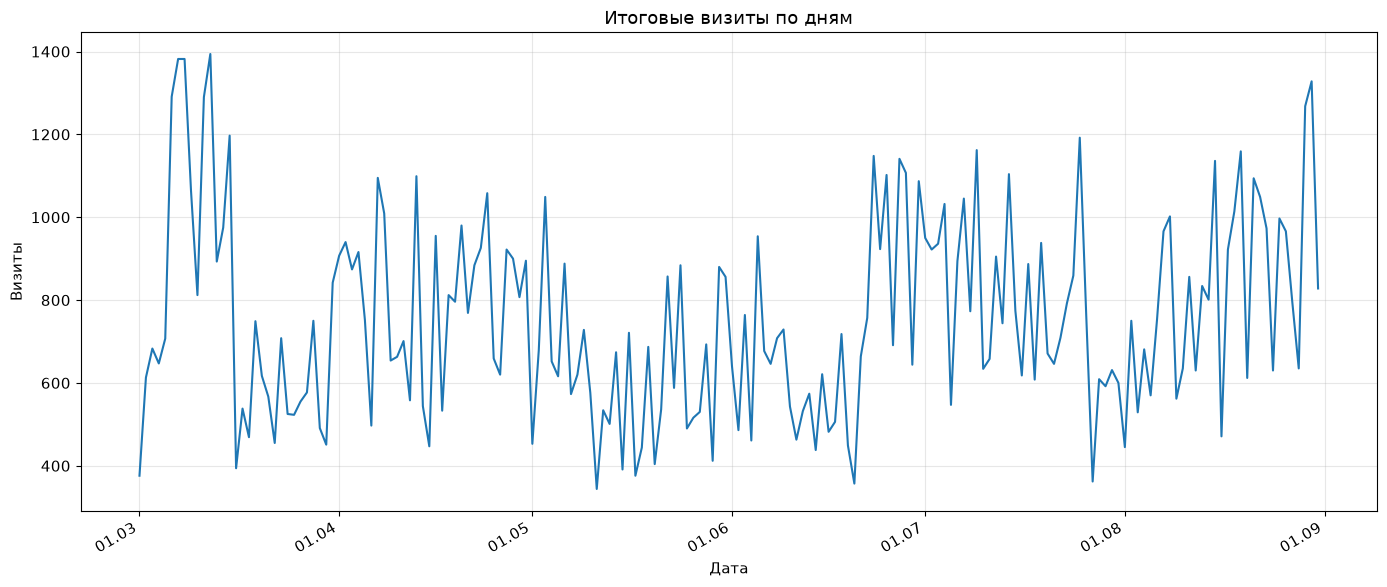

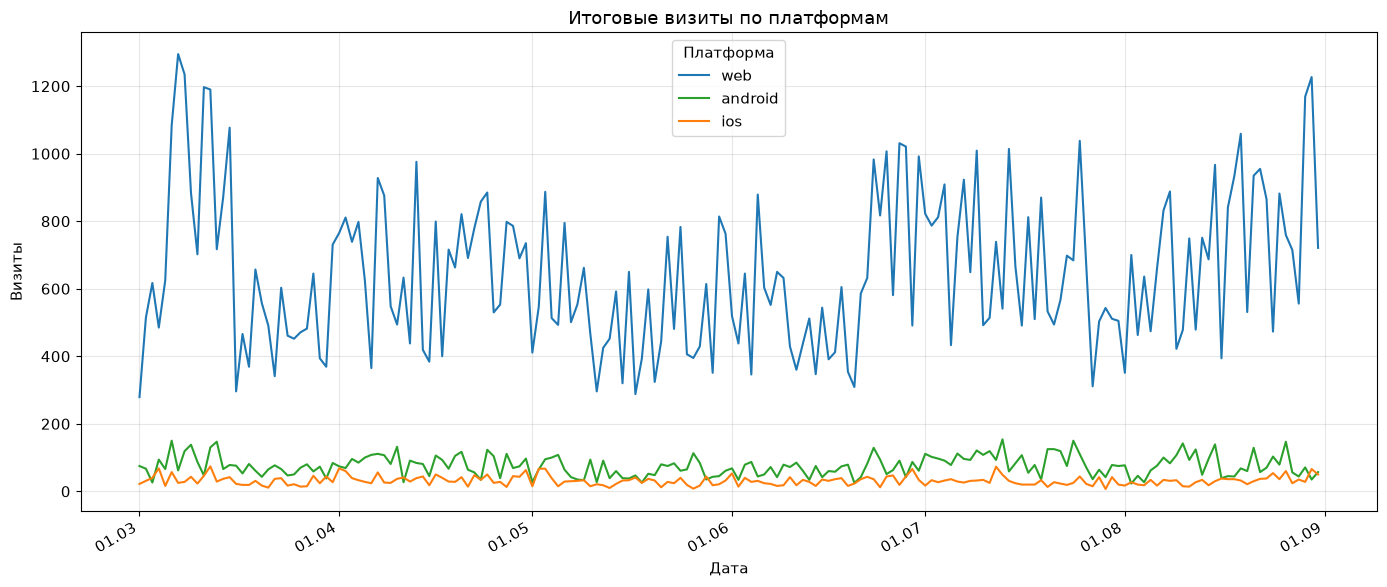

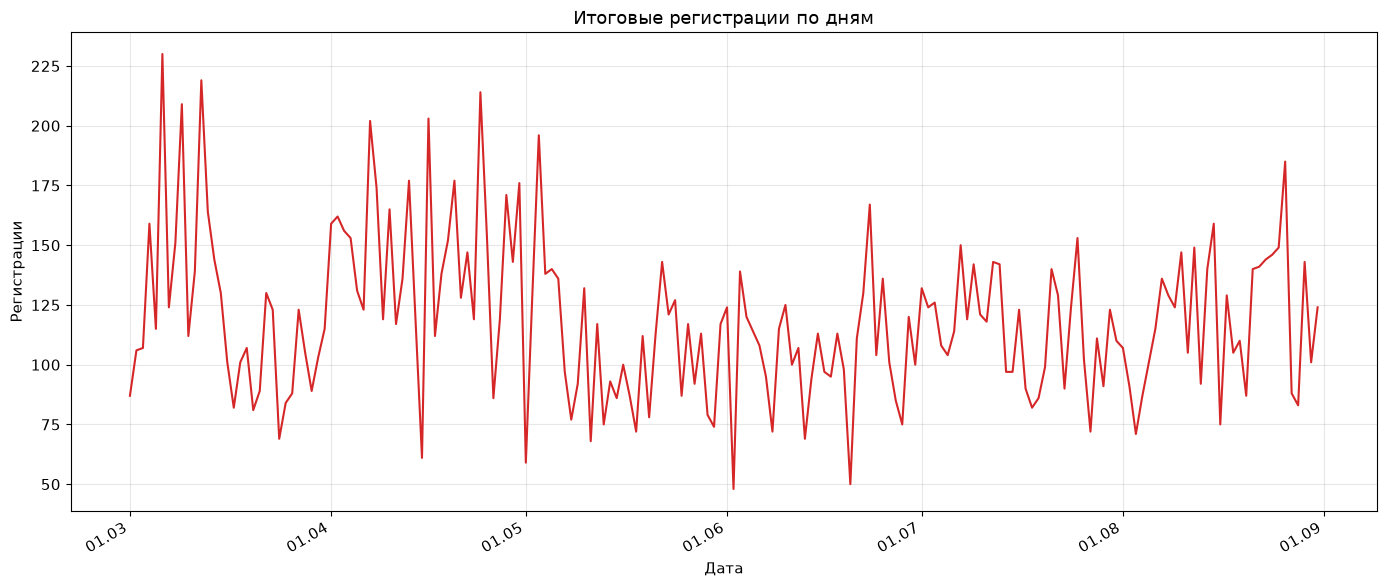

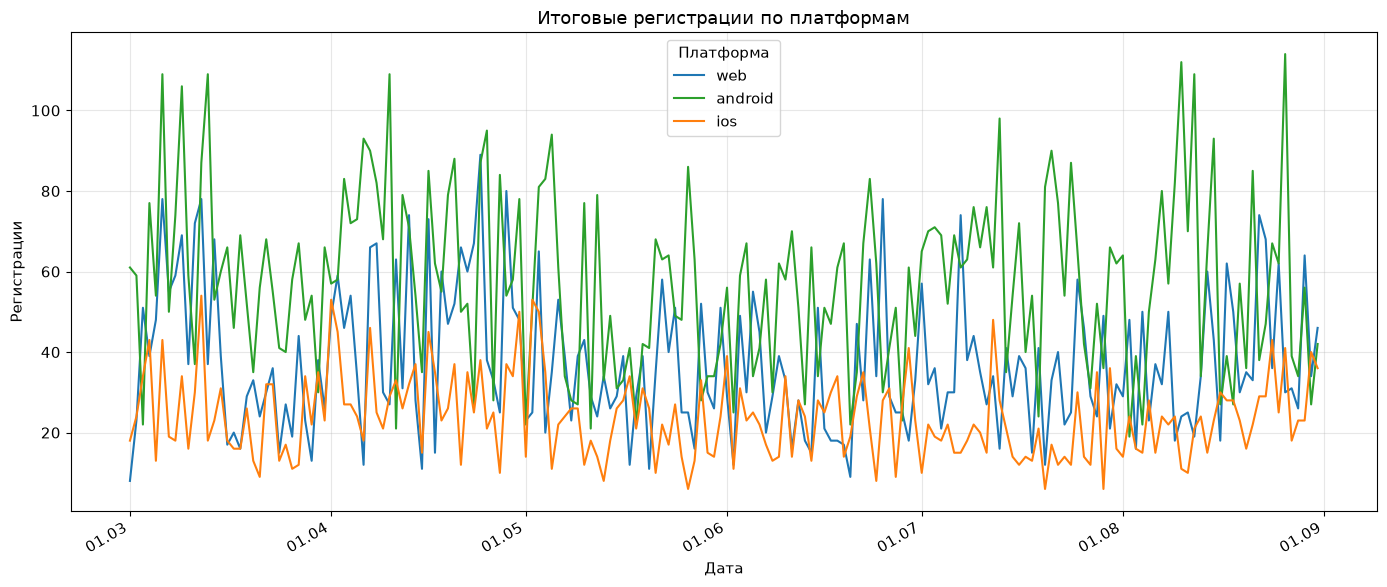

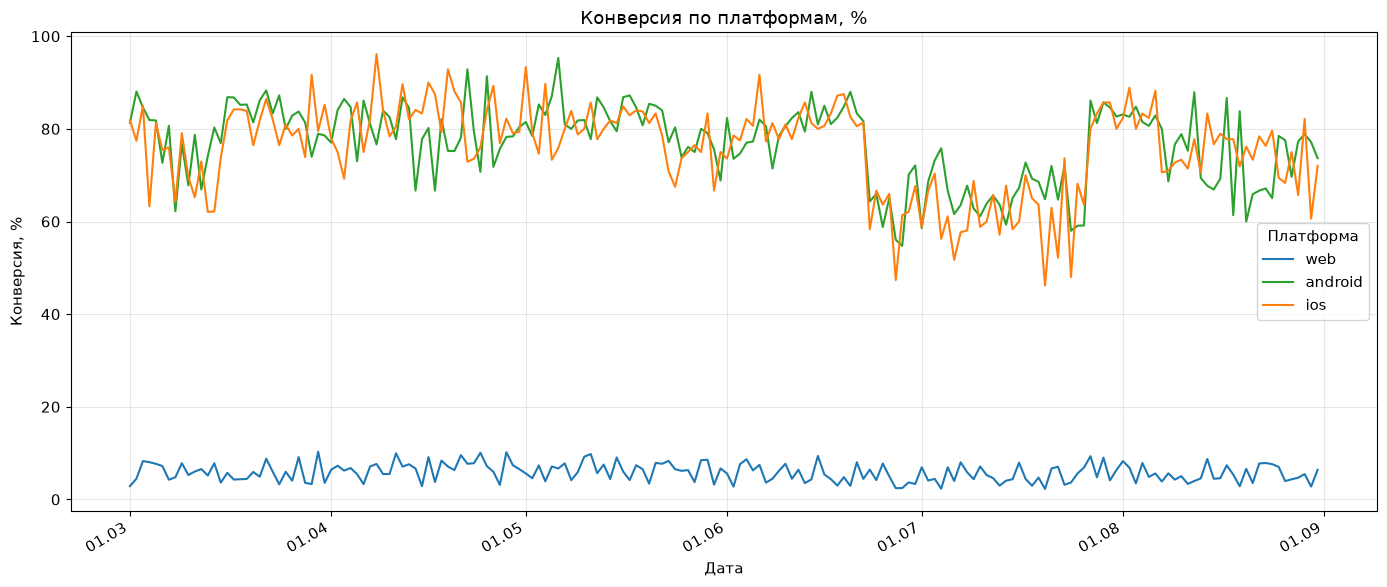

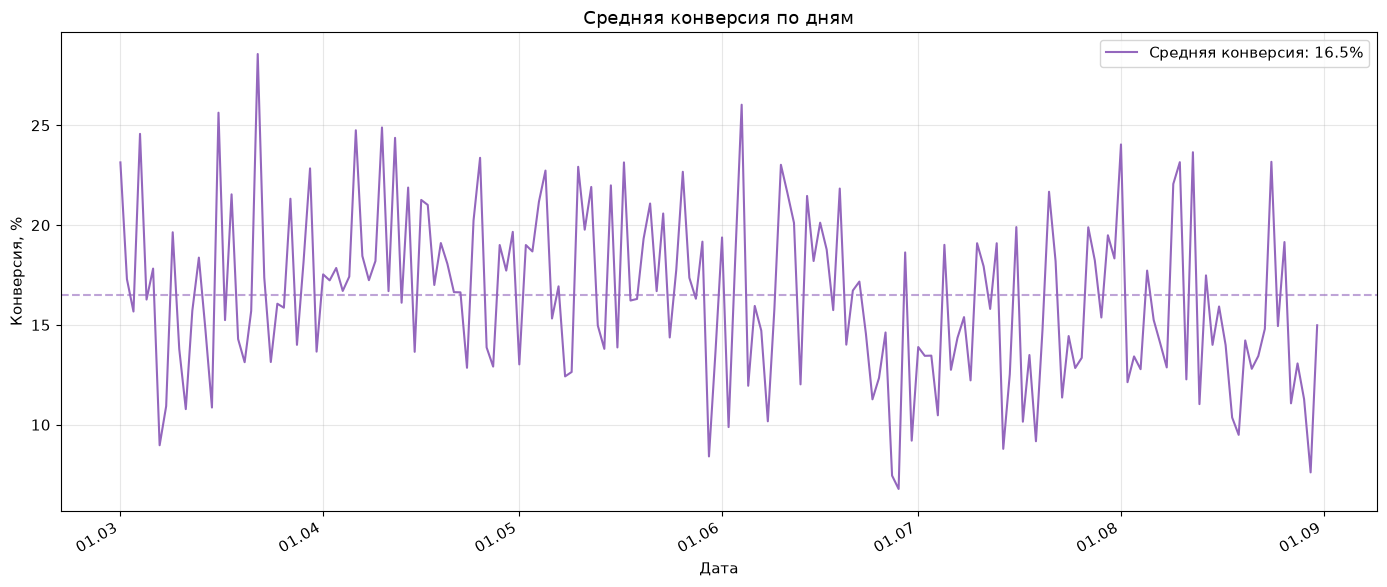

Средняя конверсия за период: 16.49%


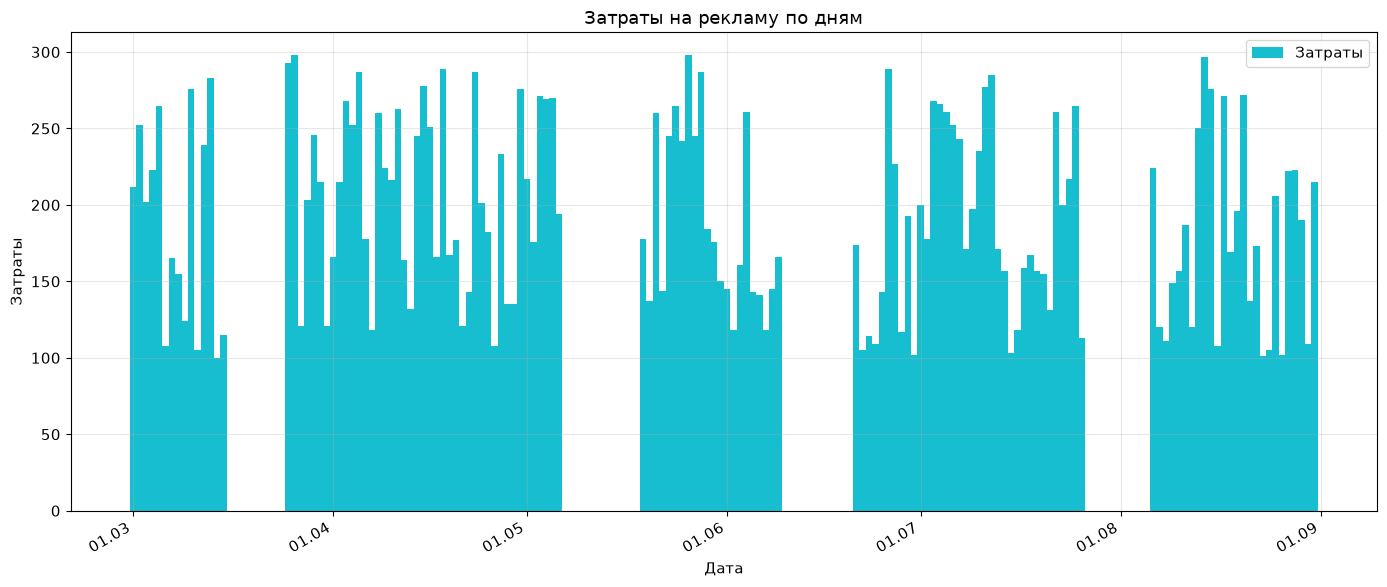

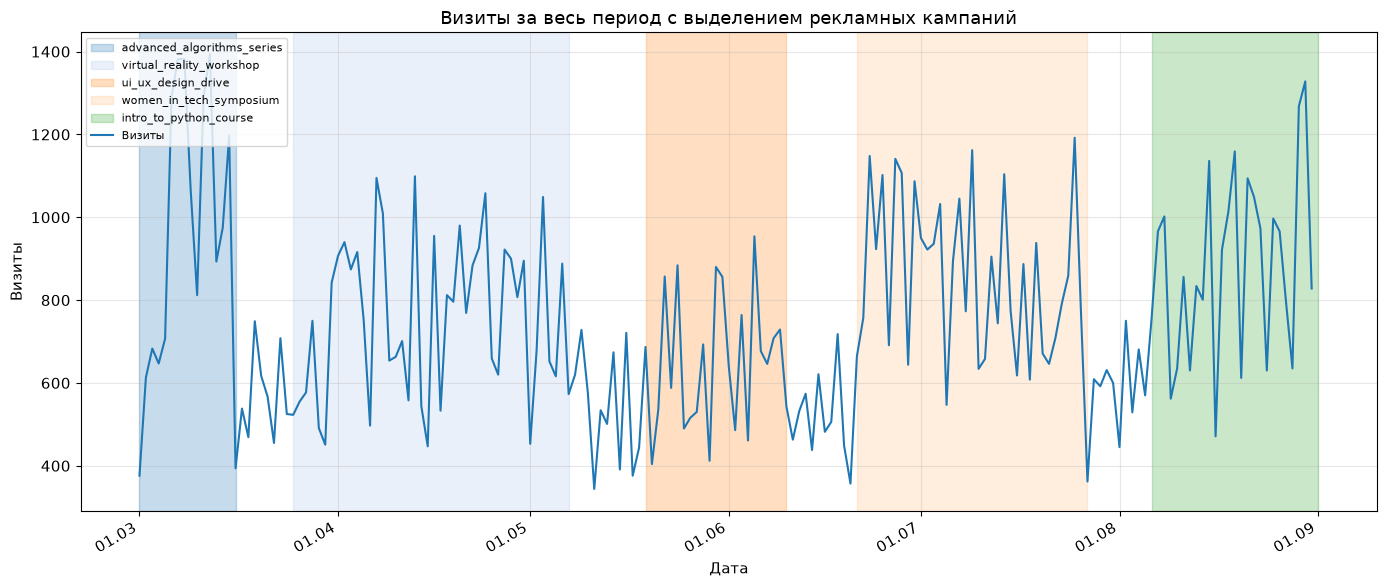

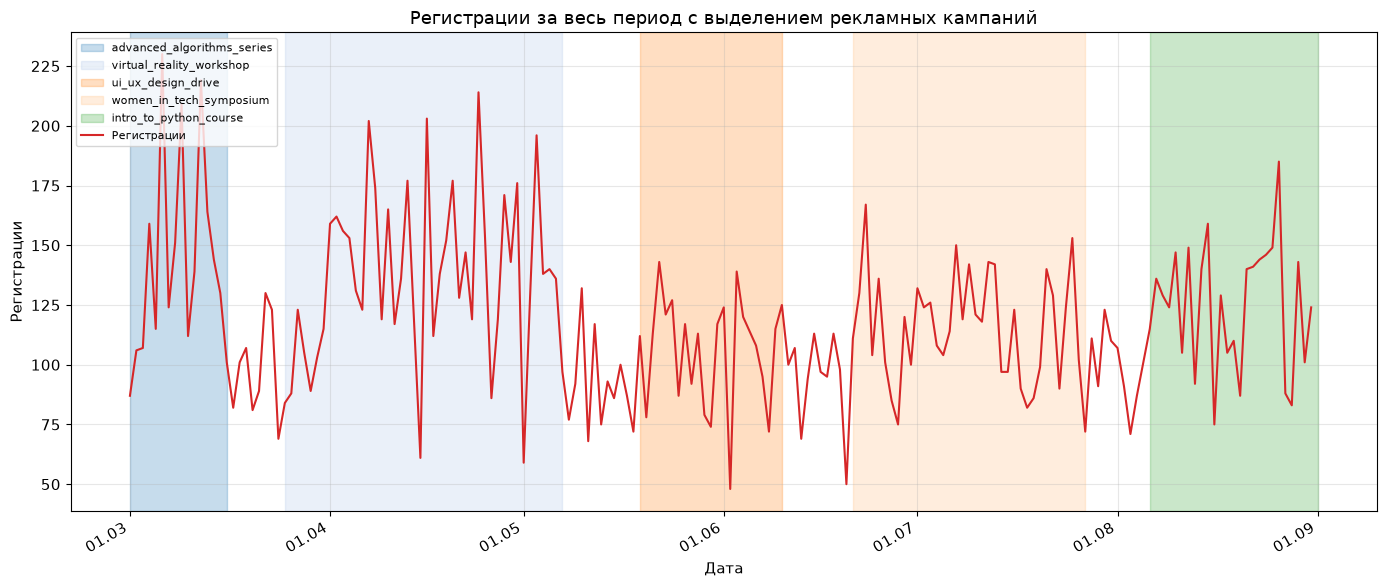

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

os.makedirs('./charts', exist_ok=True)

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

platform_colors = {'web': '#1f77b4', 'android': '#2ca02c', 'ios': '#ff7f0e'}
platforms = ['web', 'android', 'ios']

# === 1. Итоговые визиты ===
fig, ax = plt.subplots()
ax.plot(daily_cr.index, daily_cr['visits'], color='#1f77b4', linewidth=1.5)
ax.set_title('Итоговые визиты по дням'); ax.set_xlabel('Дата'); ax.set_ylabel('Визиты')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/visits.png'); plt.show()

# === 2. Визиты по платформам ===
fig, ax = plt.subplots()
for p in platforms:
    ax.plot(visits_by_platform.index, visits_by_platform[p], label=p, color=platform_colors[p])
ax.set_title('Итоговые визиты по платформам'); ax.set_xlabel('Дата'); ax.set_ylabel('Визиты')
ax.legend(title='Платформа')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/visits_by_platform.png'); plt.show()

# === 3. Итоговые регистрации ===
fig, ax = plt.subplots()
ax.plot(daily_cr.index, daily_cr['registrations'], color='#d62728', linewidth=1.5)
ax.set_title('Итоговые регистрации по дням'); ax.set_xlabel('Дата'); ax.set_ylabel('Регистрации')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/registrations.png'); plt.show()

# === 4. Регистрации по платформам ===
fig, ax = plt.subplots()
for p in platforms:
    ax.plot(regs_by_platform.index, regs_by_platform[p], label=p, color=platform_colors[p])
ax.set_title('Итоговые регистрации по платформам'); ax.set_xlabel('Дата'); ax.set_ylabel('Регистрации')
ax.legend(title='Платформа')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/registrations_by_platform.png'); plt.show()

# === 5. Конверсия по каждой платформе ===
fig, ax = plt.subplots()
for p in platforms:
    ax.plot(cr_by_platform.index, cr_by_platform[p], label=p, color=platform_colors[p])
ax.set_title('Конверсия по платформам, %'); ax.set_xlabel('Дата'); ax.set_ylabel('Конверсия, %')
ax.legend(title='Платформа')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/conversion_by_platform.png'); plt.show()

# === 6. Средняя конверсия ===
mean_cr = daily_cr['conversion'].mean()
fig, ax = plt.subplots()
ax.plot(daily_cr.index, daily_cr['conversion'], color='#9467bd', linewidth=1.5,
        label=f'Средняя конверсия: {mean_cr:.1f}%')
ax.axhline(mean_cr, color='#9467bd', linestyle='--', alpha=0.6)
ax.set_title('Средняя конверсия по дням'); ax.set_xlabel('Дата'); ax.set_ylabel('Конверсия, %')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/average_conversion.png'); plt.show()
print(f'Средняя конверсия за период: {mean_cr:.2f}%')

# === 7. Стоимости рекламы ===
fig, ax = plt.subplots()
ax.bar(ads_df['date_group'], ads_df['cost'], color='#17becf', width=1.0, label='Затраты')
ax.set_title('Затраты на рекламу по дням'); ax.set_xlabel('Дата'); ax.set_ylabel('Затраты')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/ads_costs.png'); plt.show()

# === 8. Визиты и регистрации с выделением кампаний ===
cmap = plt.get_cmap('tab20')
campaign_colors = {c['campaign']: cmap(i % 20) for i, c in enumerate(campaign_periods)}

fig, ax = plt.subplots()
for c in campaign_periods:
    ax.axvspan(c['start'], c['end'] + pd.Timedelta(days=1),
               color=campaign_colors[c['campaign']], alpha=0.25, label=c['campaign'])
ax.plot(daily_cr.index, daily_cr['visits'], color='#1f77b4', linewidth=1.5, label='Визиты')
ax.set_title('Визиты за весь период с выделением рекламных кампаний')
ax.set_xlabel('Дата'); ax.set_ylabel('Визиты')
ax.legend(loc='upper left', fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/visits_with_campaigns.png'); plt.show()

fig, ax = plt.subplots()
for c in campaign_periods:
    ax.axvspan(c['start'], c['end'] + pd.Timedelta(days=1),
               color=campaign_colors[c['campaign']], alpha=0.25, label=c['campaign'])
ax.plot(daily_cr.index, daily_cr['registrations'], color='#d62728', linewidth=1.5, label='Регистрации')
ax.set_title('Регистрации за весь период с выделением рекламных кампаний')
ax.set_xlabel('Дата'); ax.set_ylabel('Регистрации')
ax.legend(loc='upper left', fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
fig.autofmt_xdate(); plt.tight_layout()
plt.savefig('./charts/registrations_with_campaigns.png'); plt.show()


In [11]:
import glob
for f in sorted(glob.glob('./charts/*.png')):
    print(f)


./charts\ads_costs.png
./charts\average_conversion.png
./charts\conversion_by_platform.png
./charts\registrations.png
./charts\registrations_by_platform.png
./charts\registrations_with_campaigns.png
./charts\visits.png
./charts\visits_by_platform.png
./charts\visits_with_campaigns.png


In [3]:
import os

# Показываем все файлы в текущей папке проекта
files = os.listdir('.')
for f in files:
    if f.endswith('.csv') or f.endswith('.xlsx'):
        print(f"Найден файл: {f}")


Найден файл: regs_1k.csv
Найден файл: visits_1k.csv


In [4]:
import pandas as pd

# Загружаем обе таблицы
regs = pd.read_csv('regs_1k.csv')
visits = pd.read_csv('visits_1k.csv')

print("=== Регистрации (regs) ===")
print("Размер:", regs.shape)          # сколько строк и столбцов
print(regs.head())                    # первые 5 строк

print("\n=== Визиты (visits) ===")
print("Размер:", visits.shape)
print(visits.head())

print("\n=== Основная статистика по регистрациям ===")
print(regs.describe())

print("\n=== Основная статистика по визитам ===")
print(visits.describe())


=== Регистрации (regs) ===
Размер: (1000, 5)
                  date  user_id                    email platform  \
0  2023-03-01T00:25:39  8838849     joseph95@example.org      web   
1  2023-03-01T14:53:01  8741065  janetsuarez@example.net      web   
2  2023-03-01T14:27:36  1866654     robert67@example.org      web   
3  2023-03-01T02:42:34  1577584         elam@example.net      web   
4  2023-03-01T10:27:14  4765395  stephanie68@example.net      web   

  registration_type  
0            google  
1            yandex  
2            google  
3             apple  
4            yandex  

=== Визиты (visits) ===
Размер: (1000, 4)
                                   uuid platform  \
0  1de9ea66-70d3-4a1f-8735-df5ef7697fb9      web   
1  f149f542-e935-4870-9734-6b4501eaf614      web   
2  f149f542-e935-4870-9734-6b4501eaf614      web   
3  08f0ebd4-950c-4dd9-8e97-b5bdf073eed1      web   
4  08f0ebd4-950c-4dd9-8e97-b5bdf073eed1      web   

                                          user_agent

In [5]:
import pandas as pd

# === 1. Типы данных и пропуски ===
print("=" * 60)
print("ТИПЫ ДАННЫХ И ПРОПУСКИ")
print("=" * 60)

print("\n--- regs (регистрации) ---")
print(regs.info())

print("\n--- visits (визиты) ---")
print(visits.info())

# === 2. describe: числовой и категориальный режим ===
print("\n" + "=" * 60)
print("DESCRIBE: ЧИСЛОВЫЕ КОЛОНКИ")
print("=" * 60)
print("\n--- regs.describe() ---")
print(regs.describe())          # по умолчанию считает только числа (user_id)

print("\n--- visits.describe() ---")
print(visits.describe())        # если чисел нет, покажет категориальный режим

print("\n" + "=" * 60)
print("DESCRIBE: ВСЕ КОЛОНКИ, ВКЛЮЧАЯ ТЕКСТОВЫЕ")
print("=" * 60)
print("\n--- regs.describe(include='all') ---")
print(regs.describe(include='all'))

print("\n--- visits.describe(include='all') ---")
print(visits.describe(include='all'))

# === 3. Уникальные значения ключевых категорий ===
print("\n" + "=" * 60)
print("КАТЕГОРИИ: ЧТО ВСТРЕЧАЕТСЯ В ДАННЫХ")
print("=" * 60)

print("\n--- regs: platform ---")
print(regs['platform'].value_counts())

print("\n--- regs: registration_type ---")
print(regs['registration_type'].value_counts())

print("\n--- visits: platform ---")
print(visits['platform'].value_counts())

# === 4. Даты: с какого по какой период данные ===
print("\n" + "=" * 60)
print("ПЕРИОД ДАННЫХ")
print("=" * 60)

regs['date_dt'] = pd.to_datetime(regs['date'])
visits['date_dt'] = pd.to_datetime(visits['date'])

print(f"Регистрации: с {regs['date_dt'].min()} по {regs['date_dt'].max()}")
print(f"Визиты:      с {visits['date_dt'].min()} по {visits['date_dt'].max()}")

# === 5. Дубликаты и целостность ===
print("\n" + "=" * 60)
print("ДУБЛИКАТЫ И КАЧЕСТВО ДАННЫХ")
print("=" * 60)

print(f"Полных дубликатов в regs: {regs.duplicated().sum()}")
print(f"Полных дубликатов в visits: {visits.duplicated().sum()}")
print(f"Уникальных user_id в regs: {regs['user_id'].nunique()} из {len(regs)} строк")
print(f"Уникальных uuid в visits: {visits['uuid'].nunique()} из {len(visits)} строк")

# Совпадают ли пользователи между таблицами
common = set(regs['user_id'].astype(str)) & set(visits['uuid'].astype(str))
print(f"Пересечение user_id (regs) и uuid (visits): {len(common)} совпадений")


ТИПЫ ДАННЫХ И ПРОПУСКИ

--- regs (регистрации) ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   date               1000 non-null   str  
 1   user_id            1000 non-null   int64
 2   email              1000 non-null   str  
 3   platform           1000 non-null   str  
 4   registration_type  1000 non-null   str  
dtypes: int64(1), str(4)
memory usage: 39.2 KB
None

--- visits (визиты) ---
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   uuid        1000 non-null   str  
 1   platform    1000 non-null   str  
 2   user_agent  1000 non-null   str  
 3   date        1000 non-null   str  
dtypes: str(4)
memory usage: 31.4 KB
None

DESCRIBE: ЧИСЛОВЫЕ КОЛОНКИ

--- regs.describe() ---
            user_id
count  1.0000

In [6]:
# Полный список колонок и платформы
print("Колонки visits:", visits.columns.tolist())
print("\nПлатформы в visits:")
print(visits['platform'].value_counts())
print("\nПлатформы в regs:")
print(regs['platform'].value_counts())
print("\nТипы регистрации:")
print(regs['registration_type'].value_counts())
print("\nВизитов на одного человека:")
print(visits['uuid'].value_counts().head(10))


Колонки visits: ['uuid', 'platform', 'user_agent', 'date', 'date_dt']

Платформы в visits:
platform
web        954
android     27
ios         19
Name: count, dtype: int64

Платформы в regs:
platform
android    517
web        265
ios        218
Name: count, dtype: int64

Типы регистрации:
registration_type
email     446
google    303
apple     178
yandex     73
Name: count, dtype: int64

Визитов на одного человека:
uuid
251a0926-ece3-4d77-aa42-ab569fdf9fe2    4
4ac5e7fb-052b-47d0-845e-6cef973ef46b    4
04762a22-3c9f-40c9-9ac9-6628c4381836    3
7bf78a4d-9f8f-4ffb-a5f8-0a0a58994953    3
44365862-5af0-43e0-99a5-4a0d7b25331f    3
37106d20-8ead-41c8-9348-486129fc1d9d    3
a99226f4-46db-4bc4-aa8f-69260a228ba8    3
f0689ae1-1e95-4a7d-84e1-45896fa19d46    3
949606b3-283c-4412-b6a1-1b92cf58440c    3
e50008d8-0c38-4144-b6d2-88d4652ea613    3
Name: count, dtype: int64


In [8]:
# Распределение числа визитов на человека
v_per_user = visits['uuid'].value_counts()
print("Визитов на человека:")
print(v_per_user.value_counts().sort_index())   # сколько людей зашли 1, 2, 3 раза

# Регистрации по дням
regs['day'] = regs['date_dt'].dt.date
print("\nРегистрации по дням:")
print(regs.groupby('day').size())

# Визиты по дням
visits['day'] = visits['date_dt'].dt.date
print("\nВизиты по дням:")
print(visits.groupby('day').size())


Визитов на человека:
count
1    123
2    313
3     81
4      2
Name: count, dtype: int64

Регистрации по дням:
day
2023-03-01     60
2023-03-02    320
2023-03-03    279
2023-03-04    288
2023-03-05     53
dtype: int64

Визиты по дням:
day
2023-03-01    510
2023-03-02    149
2023-03-03     98
2023-03-04    105
2023-03-05     94
2023-03-06     40
2023-03-07      4
dtype: int64


In [9]:
import requests
import pandas as pd

# --- Параметры запроса ---
base_url = "https://data-charts-api.hexlet.app"
start_date = "2023-03-01"
end_date = "2023-09-01"

# --- Запрос визитов ---
visits_url = f"{base_url}/visits"
visits_params = {"begin": start_date, "end": end_date}

print(f"Запрашиваем визиты: {visits_url}?begin={start_date}&end={end_date}")
visits_response = requests.get(visits_url, params=visits_params)
visits_response.raise_for_status()  # Вызовет ошибку, если API вернёт 4xx/5xx
visits_data = visits_response.json()

# --- Запрос регистраций ---
regs_url = f"{base_url}/registrations"
regs_params = {"begin": start_date, "end": end_date}

print(f"Запрашиваем регистрации: {regs_url}?begin={start_date}&end={end_date}")
regs_response = requests.get(regs_url, params=regs_params)
regs_response.raise_for_status()
regs_data = regs_response.json()

# --- Превращаем в DataFrame ---
visits = pd.DataFrame(visits_data)
regs = pd.DataFrame(regs_data)

# --- Приводим типы и переименовываем колонки для удобства (как в старых файлах) ---
# Визиты: visit_id -> uuid, datetime -> date
visits = visits.rename(columns={"visit_id": "uuid", "datetime": "date"})
visits['date_dt'] = pd.to_datetime(visits['date'])

# Регистрации: user_id, datetime -> date
regs = regs.rename(columns={"datetime": "date"})
regs['date_dt'] = pd.to_datetime(regs['date'])

# --- Быстрый чек-ап: сколько строк пришло ---
print("\n=== ИТОГИ ЗАГРУЗКИ ===")
print(f"Визитов получено: {len(visits)}")
print(f"Регистраций получено: {len(regs)}")
print(f"Период визитов: с {visits['date_dt'].min()} по {visits['date_dt'].max()}")
print(f"Период регистраций: с {regs['date_dt'].min()} по {regs['date_dt'].max()}")

# --- Сохраняем в CSV (на случай, если интернет пропадёт или API будет недоступен) ---
visits.to_csv("visits_api.csv", index=False)
regs.to_csv("regs_api.csv", index=False)
print("\nДанные сохранены в visits_api.csv и regs_api.csv")


Запрашиваем визиты: https://data-charts-api.hexlet.app/visits?begin=2023-03-01&end=2023-09-01
Запрашиваем регистрации: https://data-charts-api.hexlet.app/registrations?begin=2023-03-01&end=2023-09-01

=== ИТОГИ ЗАГРУЗКИ ===
Визитов получено: 263459
Регистраций получено: 21836
Период визитов: с 2023-03-01 00:00:43 по 2023-08-31 23:52:57
Период регистраций: с 2023-03-01 00:04:47 по 2023-08-31 23:43:26

Данные сохранены в visits_api.csv и regs_api.csv


In [10]:
import pandas as pd

# === describe по всем колонкам ===
print("=== РЕГИСТРАЦИИ: describe ===")
print(regs.describe(include='all'))

print("\n=== ВИЗИТЫ: describe ===")
print(visits.describe(include='all'))

# === Динамика по месяцам ===
print("\n=== Визиты по месяцам ===")
print(visits['date_dt'].dt.to_period('M').value_counts().sort_index())

print("\n=== Регистрации по месяцам ===")
print(regs['date_dt'].dt.to_period('M').value_counts().sort_index())

# === Качество данных на большом объёме ===
print("\n=== КАЧЕСТВО ===")
print(f"Пропуски в visits: {visits.isna().sum().sum()}")
print(f"Пропуски в regs: {regs.isna().sum().sum()}")
print(f"Уникальных visit_id: {visits['uuid'].nunique()} из {len(visits)}")
print(f"Уникальных user_id: {regs['user_id'].nunique()} из {len(regs)}")
print(f"Полных дубликатов: visits={visits.duplicated().sum()}, regs={regs.duplicated().sum()}")


=== РЕГИСТРАЦИИ: describe ===
                       date                               user_id  \
count                 21836                                 21836   
unique                21821                                 21836   
top     2023-03-01T09:53:07  2e0f6bb8-b029-4f45-a786-2b53990d37f1   
freq                      2                                     1   
mean                    NaN                                   NaN   
min                     NaN                                   NaN   
25%                     NaN                                   NaN   
50%                     NaN                                   NaN   
75%                     NaN                                   NaN   
max                     NaN                                   NaN   

                     email platform registration_type  \
count                21836    21836             21836   
unique               20868        3                 4   
top     ujones@example.com  android    

In [11]:
# === Платформы и боты ===
print("=== Платформы визитов ===")
print(visits['platform'].value_counts())

print("\n=== Платформы регистраций ===")
print(regs['platform'].value_counts())

# === Динамика по месяцам ===
print("\n=== Визиты по месяцам ===")
print(visits['date_dt'].dt.to_period('M').value_counts().sort_index())

print("\n=== Регистрации по месяцам ===")
print(regs['date_dt'].dt.to_period('M').value_counts().sort_index())

# === Грубая конверсия по месяцам ===
v_m = visits['date_dt'].dt.to_period('M').value_counts().sort_index()
r_m = regs['date_dt'].dt.to_period('M').value_counts().sort_index()
conv = (r_m / v_m * 100).round(2)
print("\n=== Конверсия визит->регистрация по месяцам, % ===")
print(conv)

# === Повторные email: сколько людей с одинаковой почтой ===
email_dup = regs[regs.duplicated('email', keep=False)]
print(f"\nЗаписей с повторяющимся email: {len(email_dup)}")


=== Платформы визитов ===
platform
web        236301
android     13972
bot          7382
ios          5804
Name: count, dtype: int64

=== Платформы регистраций ===
platform
android    10582
web         6877
ios         4377
Name: count, dtype: int64

=== Визиты по месяцам ===
date_dt
2023-03    46572
2023-04    45425
2023-05    36542
2023-06    41247
2023-07    45984
2023-08    47689
Freq: M, Name: count, dtype: int64

=== Регистрации по месяцам ===
date_dt
2023-03    3786
2023-04    4393
2023-05    3267
2023-06    3125
2023-07    3562
2023-08    3703
Freq: M, Name: count, dtype: int64

=== Конверсия визит->регистрация по месяцам, % ===
date_dt
2023-03    8.13
2023-04    9.67
2023-05    8.94
2023-06    7.58
2023-07    7.75
2023-08    7.76
Freq: M, Name: count, dtype: float64

Записей с повторяющимся email: 1808


In [12]:
# === Регистрации по месяцам (обрезалось в выводе) ===
print("=== Регистрации по месяцам ===")
print(regs['date_dt'].dt.to_period('M').value_counts().sort_index())

# === Полная конверсия по месяцам ===
v_m = visits['date_dt'].dt.to_period('M').value_counts().sort_index()
r_m = regs['date_dt'].dt.to_period('M').value_counts().sort_index()
conv = pd.DataFrame({'visits': v_m, 'registrations': r_m})
conv['conversion_%'] = (conv['registrations'] / conv['visits'] * 100).round(2)
print("\n=== Конверсия визит -> регистрация по месяцам ===")
print(conv)

# === Конверсия без ботов ===
visits_clean = visits[visits['platform'] != 'bot']
vc = visits_clean['date_dt'].dt.to_period('M').value_counts().sort_index()
print("\n=== Конверсия без ботов, % ===")
print((r_m / vc * 100).round(2))

# === Пример повторных email: что там за записи ===
dup_emails = regs[regs['email'].duplicated(keep=False)].sort_values('email')
print(f"\nПример записей с одинаковым email:")
print(dup_emails[['email', 'platform', 'registration_type', 'date_dt']].head(10))


=== Регистрации по месяцам ===
date_dt
2023-03    3786
2023-04    4393
2023-05    3267
2023-06    3125
2023-07    3562
2023-08    3703
Freq: M, Name: count, dtype: int64

=== Конверсия визит -> регистрация по месяцам ===
         visits  registrations  conversion_%
date_dt                                     
2023-03   46572           3786          8.13
2023-04   45425           4393          9.67
2023-05   36542           3267          8.94
2023-06   41247           3125          7.58
2023-07   45984           3562          7.75
2023-08   47689           3703          7.76

=== Конверсия без ботов, % ===
date_dt
2023-03    8.35
2023-04    9.94
2023-05    9.22
2023-06    7.82
2023-07    7.97
2023-08    7.97
Freq: M, Name: count, dtype: float64

Пример записей с одинаковым email:
                        email platform registration_type             date_dt
15519   aanderson@example.net  android            google 2023-07-08 13:37:04
1211    aanderson@example.net  android            google